# Anatomie d'une alerte : le 22 mars 2020

Le 13 mars 2020, New York déclare l'état d'urgence. Ce notebook rejoue, jour par jour, ce
que le moniteur ZoneFleet aurait vu, sans aucun label, jusqu'à la première page ; puis ce
que les labels révèlent deux mois plus tard.

Prérequis : le cache des prévisions (`make e0`).

In [1]:
import os
os.environ["NML_DISABLE_USAGE_LOGGING"] = "1"

import pandas as pd

from zonefleet.alerting import daily_signals, policy_flags
from zonefleet.monitoring import monitor
from zonefleet.pipeline import predictions

p = predictions("covid")
ref, an = p[p.period == "reference"], p[p.period == "analysis"]
out = monitor(ref, an)
sig = daily_signals(out)
flags = policy_flags(sig)
window = sig.loc["2020-03-09":"2020-03-25"]
cols = ["psi_clean_max", "pca_alert", "drift_clean", "estimated", "threshold", "perf_est"]
window[cols].round(3)

2026/11/23 20:16:22 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at /home/wilsjazz/Workspace/MLOps_TS/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/mlflow-trace-instrumentation/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,psi_clean_max,pca_alert,drift_clean,estimated,threshold,perf_est
date,,,,,,
2020-03-09,0.115,False,False,0.208,0.423,False
2020-03-10,0.073,False,False,0.181,0.423,False
2020-03-11,0.052,False,False,0.182,0.423,False
2020-03-12,0.062,False,False,0.200,0.423,False
2020-03-13,0.083,False,False,0.194,0.423,False
2020-03-14,0.335,False,True,0.211,0.423,False
2020-03-15,1.385,False,True,0.238,0.423,False
2020-03-16,2.141,False,True,0.316,0.423,False
2020-03-17,1.747,False,True,0.308,0.423,False


## Ce qu'on lit dans ce tableau

- Le **PSI des lags** dépasse 0,25 dès le 14 mars : la dérive nettoyée s'allume
  (la demande d'hier ne ressemble plus à celle de l'automne).
- La **PCA** ne voit presque rien (une seule journée, le 23) : les lags chutent ensemble,
  le long de la première composante.
- La **perte estimée** monte lentement et ne franchit son seuil que le 19, puis durablement
  à partir du 22 : il faut que les lags aient absorbé le choc pour que DLE le voie.

In [2]:
cols = ["P1b_drift_clean", "P2_dle", "P3b_clean_and_dle"]
flags.loc["2020-03-09":"2020-03-25", cols]

,P1b_drift_clean,P2_dle,P3b_clean_and_dle
date,,,
2020-03-09,False,False,False
2020-03-10,False,False,False
2020-03-11,False,False,False
2020-03-12,False,False,False
2020-03-13,False,False,False
2020-03-14,False,False,False
2020-03-15,True,False,False
2020-03-16,True,False,False
2020-03-17,True,False,False


La condition jointe nettoyée (P3b) s'allume le **23 mars** (jour cible) : la décision
est possible la veille, le **22 mars**, neuf jours après l'état d'urgence. La dérive
nettoyée seule (P1b) aurait alerté dès le 14 mars, mais elle alerte aussi sur des dérives
bénignes (E4) : elle ouvre un ticket, pas une page.

In [3]:
from zonefleet.cli import daily_report

print(daily_report("covid", "2020-03-23"))

# Monitoring ZoneFleet : 2020-03-23

**Sévérité : INCIDENT DONNÉES** · modèle `zonefleet-demand` v1

## Signaux du jour

| Signal | Valeur | Seuil | État |
|---|---|---|---|
| perte estimée (MAE log, DLE) | 0,424 | 0,423 | au-dessus |
| dérive nettoyée (PCA ou PSI lags) | oui | - | dérive |
| perte réalisée (labels) | - | 0,423 | en attente |

## Qualité des données (avant le modèle)

- volume / médiane des 4 mêmes jours : 0,07
- corrélation du profil horaire : 0,855
- zones sans aucune course : 0

> Incident données : traiter l'amont avant toute lecture des signaux du modèle ; exclure ces jours de tout réentraînement.

## Zones en tête de perte estimée

| Zone | Perte estimée |
|---|---|
| 138 LaGuardia Airport | 0,685 |
| 161 Midtown Center | 0,571 |
| 231 TriBeCa/Civic Center | 0,555 |
| 158 Meatpacking/West Village West | 0,552 |
| 13 Battery Park City | 0,525 |

## Features en dérive (PSI > 0,25)

- `roll_mean_168` : 6,28
- `lag_24` : 5,99
- `temperature_2m` : 5,95
- `lag_168` : 1

## Deux mois plus tard : ce que disent les labels

,estimated,realized
date,,
2020-03-22,0.476,1.748
2020-03-23,0.424,1.728
2020-03-24,0.448,1.541
2020-03-25,0.475,1.521
2020-03-26,0.530,1.490
2020-03-27,0.485,1.359
2020-03-28,0.472,1.451


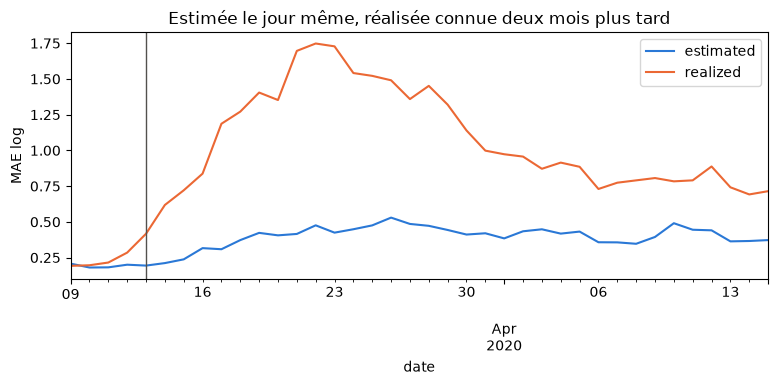

In [4]:
late = sig.loc["2020-03-09":"2020-04-15", ["estimated", "realized"]]
ax = late.plot(figsize=(9, 3.2), color=["#2a78d6", "#eb6834"])
ax.axvline(pd.Timestamp("2020-03-13"), color="#52514e", lw=1)
ax.set_ylabel("MAE log")
ax.set_title("Estimée le jour même, réalisée connue deux mois plus tard")
late.loc["2020-03-22":"2020-03-28"].round(3)

L'erreur réelle de ces journées est de 1,4 à 1,7, soit près de trois à quatre fois
l'estimation :
la page était juste sur le **fait** (le modèle se dégrade) et fausse sur l'**ampleur**.
C'est exactement la frontière mesurée dans E3 : pendant la transition, le choc ressemble à
un concept drift, que la perte estimée ne peut voir qu'en partie.